# 02 Demand-gap score
Weighted score per LSOA (higher = bigger gap between need and provision), plus sensitivity analysis.
Input: `data/clean/lsoa_base.parquet`. Run from the `notebooks/` folder.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = Path("../data/clean")
df = pd.read_parquet(CLEAN / "lsoa_base.parquet")
freq = pd.read_parquet(CLEAN / "lsoa_frequency.parquet")   # from notebook 04 (GTFS)
df = df.merge(freq, on="LSOA21CD", how="left")
df.shape

(33755, 16)

## 1. Components
Each oriented so higher = worse provision or higher need.

`supply` is now **real service frequency**: mean departures per hour across the three time bands (from GTFS), per 1,000 residents, log-scaled. Zero service gives the worst value.

In [2]:
# Average of the three time bands (07-19), in departures per hour
df["freq_mean"] = df[["freq_morning", "freq_off_peak", "freq_evening"]].mean(axis=1)
# Buses per person: departures per hour for every 1,000 residents
df["freq_per_1000"] = df["freq_mean"] / df["population"] * 1000
df["stops_per_1000"] = df["n_stops"] / df["population"] * 1000
# The four ingredients of the score. All are oriented so that a higher value = a bigger gap
comp = pd.DataFrame({
    "access": df["dist_nearest_stop_m"],   # far from a stop
    "supply": -np.log1p(df["freq_per_1000"]),   # little service per person (GTFS)
    "density": df["pop_density"],          # many people to serve
    "deprivation": df["imd_score"],        # more deprived
}, index=df.index)
comp.describe().T

,count,mean,std,min,25%,50%,75%,max
access,33755.0,274.950716,421.122320,0.485392,98.129397,168.153914,294.536266,4.576138e+04
supply,33755.0,-2.236817,1.096488,-6.320754,-2.979361,-2.327451,-1.570918,-0.000000e+00
density,33755.0,5135.550849,11069.597706,2.197836,1358.018242,3700.451063,6358.599881,1.249327e+06
deprivation,33755.0,21.669350,15.689121,0.165000,9.688500,17.450000,29.669500,9.422300e+01


## 2. Normalise (0-1)
Winsorise at the 1st and 99th percentile, then min-max.

In [3]:
# Clip to the 1st-99th percentile so outliers do not stretch the scale, then rescale to 0-1
def norm01(s, lo=0.01, hi=0.99):
    a, b = s.quantile([lo, hi])
    return (s.clip(a, b) - a) / (b - a)
N = comp.apply(norm01)
N.describe().T[["min","50%","max"]]

,min,50%,max
access,0.0,0.090442,1.0
supply,0.0,0.493216,1.0
density,0.0,0.130486,1.0
deprivation,0.0,0.231945,1.0


## 3. Weighted score
Baseline weights are **placeholders**: justify from the literature in the report.

In [4]:
# Base weights (30/30/20/20). This is a judgement call, which is why it is tested in the sensitivity section below
W = {"access": 0.30, "supply": 0.30, "density": 0.20, "deprivation": 0.20}
# Weighted sum of the 0-1 components; weights are rescaled to add up to 1
def score(weights):
    w = pd.Series(weights)[N.columns]
    return (N * (w / w.sum())).sum(axis=1)
df["gap_score"] = score(W)
df["gap_rank"] = df["gap_score"].rank(ascending=False, method="first").astype(int)
# "Worst-served" = the 10% of neighbourhoods with the highest score
df["gap_top10"] = df["gap_rank"] <= int(0.10 * len(df))
df["gap_score"].describe()

count    33755.000000
mean         0.292306
std          0.102999
min          0.026325
25%          0.220376
50%          0.277799
75%          0.349614
max          0.739488
Name: gap_score, dtype: float64

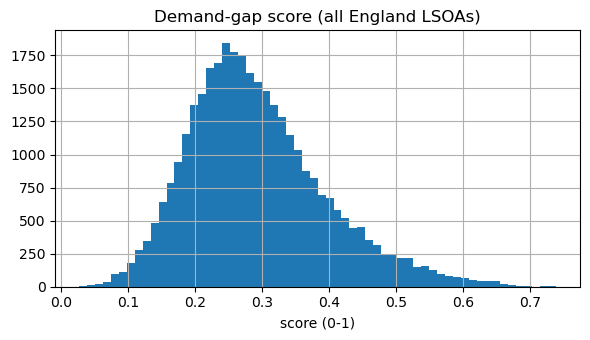

In [5]:
fig, ax = plt.subplots(figsize=(6,3.5))
df["gap_score"].hist(bins=60, ax=ax); ax.set_title("Demand-gap score (all England LSOAs)")
ax.set_xlabel("score (0-1)"); plt.tight_layout()

In [6]:
df.groupby("Urban_rura")["gap_top10"].mean().round(3)

Urban_rura
Rural    0.172
Urban    0.086
Name: gap_top10, dtype: float64

## 4. Sensitivity analysis
500 random weight sets (Dirichlet). Compare each ranking with the baseline: Spearman correlation and overlap of the top 10%.

In [7]:
# Sensitivity: draw 500 random weight sets (a Dirichlet draw gives any mix that sums to 1, including extreme ones) and compare each ranking with the base ranking
rng = np.random.default_rng(42)
base_top = set(df.index[df["gap_top10"]])
base_rank = df["gap_score"].rank()
rows = []
for i in range(500):
    w = dict(zip(N.columns, rng.dirichlet(np.ones(len(N.columns)))))
    s = score(w)
    top = set(s.nlargest(len(base_top)).index)
    rows.append({"run": i, **w,
                 "spearman_vs_base": s.rank().corr(base_rank),
                 "top10_overlap": len(top & base_top) / len(base_top)})
sens = pd.DataFrame(rows)
sens[["spearman_vs_base","top10_overlap"]].describe().round(3)

,spearman_vs_base,top10_overlap
count,500.000,500.000
mean,0.771,0.570
std,0.160,0.158
min,0.306,0.219
25%,0.673,0.456
50%,0.812,0.579
75%,0.900,0.698
max,0.998,0.959


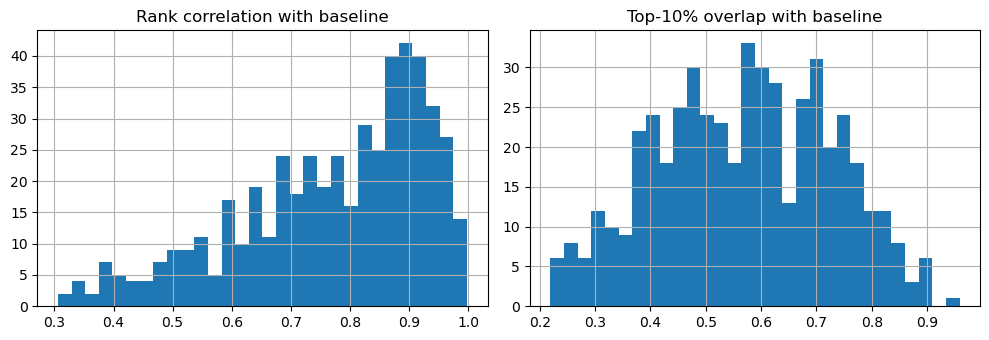

In [8]:
fig, ax = plt.subplots(1,2, figsize=(10,3.5))
sens["spearman_vs_base"].hist(bins=30, ax=ax[0]); ax[0].set_title("Rank correlation with baseline")
sens["top10_overlap"].hist(bins=30, ax=ax[1]); ax[1].set_title("Top-10% overlap with baseline")
plt.tight_layout()

In [9]:
# Named alternative weightings, compared with the baseline
alts = {
    "Equal weights (25/25/25/25)": {"access": .25, "supply": .25, "density": .25, "deprivation": .25},
    "Provision only (50/50/0/0)": {"access": .5, "supply": .5, "density": 0, "deprivation": 0},
    "Need-heavy (15/15/35/35)": {"access": .15, "supply": .15, "density": .35, "deprivation": .35},
}
rows = []
for name, w_ in alts.items():
    s_ = score(w_)
    top = set(s_.nlargest(len(base_top)).index)
    rows.append({"weights": name, "spearman_vs_baseline": s_.rank().corr(base_rank), "top10_overlap": len(top & base_top) / len(base_top)})
pd.DataFrame(rows).round(3)

,weights,spearman_vs_baseline,top10_overlap
0,Equal weights (25/25/25/25),0.968,0.804
1,Provision only (50/50/0/0),0.747,0.587
2,Need-heavy (15/15/35/35),0.745,0.476


## 5. Save

In [10]:
df.to_parquet(CLEAN / "lsoa_score.parquet", index=False)
sens.to_csv(CLEAN / "sensitivity.csv", index=False)
print("saved")

saved
